# **Practical assignment on Topic 8**

In this assignment, you have to use the dataset `auto-lpkm.tsv` given in the lecture and you should also reuse the given code.

The assignment consists of the following tasks:

**Task 1**<br>
Copy the `SFS` function from the lecture materials two times. Use the second copy to create function called `SBS` and implement the SBS algorithm (as explained in the lecture). When you run it on the given data, in its output you should see exactly the same number of iterations as SFS had. Verify correctness of the results by checking if it returns the overall best coefficient of determination as `0.8646`.

**Task 2**<br>
Step 1: Modify the SFS and SBS code so that the functions create a plot from iteration results, where X axis is the number of selected features and the Y axis is the best MSE of that iteration. Make the plotting optional with an argument of the functions.<br>
Step 2: Replace the Linear Regression model with unweighted KNN and run (without plotting) SFS and SBS for all $k$ values in range 1 to 9 (inclusive). Find the best $k$ value.

**Task 3**<br>
Run Linear Regression with SFS and SBS with plotting turned on. And run KNN with the best found $k$ value with SFS and SBS with plotting turned on. Write a short analysis of all results from this and the previous tasks, including all the plots.

---
*While doing the tasks you are allowed to use only those function libraries that were already used in the lectures so far.*

**After the tasks are done, submit this file. Do not clear it's output - all print-outs and figures should be left in the file. All your code should be fully runnable in the order of appearance and it should produce exactly the same output that is present in your print-outs and figures you left in the file.**

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_validate

In [47]:
data = pd.read_csv('./auto-lpkm.tsv', sep='\t', header=0)
X = data.to_numpy()[:, 0:-1]
y = data.to_numpy()[:, -1]
data = data.drop('l100km', axis=1)
feature_names = data.columns.values
model = LinearRegression()

# Task 1: SFS and SBS Implementation

In [48]:
def SFS(X, y, model, feature_names):
    m = X.shape[1]

    current_bits = np.full(m, False)  # the current remembered solution

    overall_best_bits = np.full(m, False)  # the overall best found solution
    overall_best_mse = np.inf  # evaluation of the best found solution

    # SFS iterations (as many iteration as there are features)
    for iter in range(1, m + 1):
        best_mse = np.inf  # best evaluation in the current iteration
        best_j = -1  # best feature in the current iteration

        # going through all features
        for j in range(0, m):
            if current_bits[j]:  # if the feature is already included, we do nothing
                continue
            current_bits[j] = True  # inclusion of the feature

            X_selected = X[:, current_bits]  # data with the selected features
            MSE = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                'test_neg_mean_squared_error'].mean()
            # if better, remember it
            if MSE < best_mse:
                best_mse = MSE
                best_j = j

            current_bits[j] = False  # remove it to get back to original vector

        current_bits[best_j] = True  # inclusion of the best found feature

        # print best result in the current iteration
        print(f'Iteration {iter}: MSE = {best_mse}')
        print(''.join(['1' if bit else '0' for bit in current_bits]) + ': ' + '\t'.join(feature_names[current_bits]))
        print()

        # if better than the overall best, remember it
        if best_mse < overall_best_mse:
            overall_best_mse = best_mse
            overall_best_bits = current_bits.copy()

    # print the overall best result
    print('Overall best MSE =', overall_best_mse)
    print(''.join(['1' if bit else '0' for bit in overall_best_bits]) + ': ' + '\t'.join(
        feature_names[overall_best_bits]))

    # in addition, compute coefficient of determination
    X_selected = X[:, overall_best_bits]
    R2 = cross_validate(model, X_selected, y, cv=10, scoring=["r2"])['test_r2'].mean()
    print('\nOverall best R2: %.3f' % R2)

In [49]:
def SBS(X, y, model, feature_names):
    m = X.shape[1]

    current_bits = np.full(m, True)  # the current remembered solution (with all features))

    overall_best_bits = np.full(m, True)  # the overall best found solution
    overall_best_mse = np.inf  # evaluation of the best found solution

    # SBS iterations (as many iterations as there are features)
    for iter in range(1, m + 1):
        if iter == 1:
            # evaluate model with all features
            X_selected = X[:, current_bits]
            best_mse = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                'test_neg_mean_squared_error'].mean()
        else:
            best_mse = np.inf
            best_j = -1

            # going through all features
            for j in range(0, m):
                if not current_bits[j]:  # if feature is already excluded, we do nothing
                    continue
                current_bits[j] = False  # removal of candidate feature

                X_selected = X[:, current_bits]  # data without candidate feature
                MSE = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                    'test_neg_mean_squared_error'].mean()
                # if better, remember it
                if MSE < best_mse:
                    best_mse = MSE
                    best_j = j

                current_bits[j] = True  # readd feature

            current_bits[best_j] = False  # removal of the feature leading  to the best MSE

        # print best result in the current iteration
        print(f'Iteration {iter}: MSE = {best_mse}')
        print(''.join(['1' if bit else '0' for bit in current_bits]) + ': ' + '\t'.join(feature_names[current_bits]))
        print()

        # if better than the overall best, remember it
        if best_mse < overall_best_mse:
            overall_best_mse = best_mse
            overall_best_bits = current_bits.copy()

    # print the overall best result
    print('Overall best MSE =', overall_best_mse)
    print(''.join(['1' if bit else '0' for bit in overall_best_bits]) + ': ' + '\t'.join(
        feature_names[overall_best_bits]))

    # in addition, compute coefficient of determination
    X_selected = X[:, overall_best_bits]
    R2 = cross_validate(model, X_selected, y, cv=10, scoring=["r2"])['test_r2'].mean()
    print('\nOverall best R2: %.4f' % R2)

In [50]:
# Run SBS with Linear Regression
SBS(X, y, model, feature_names)

Iteration 1: MSE = 2.1704843537187894
11111111111111: id	cylinders	displacement	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 2: MSE = 2.1376427808690637
11011111111111: id	cylinders	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 3: MSE = 2.1080443914583924
11011111011111: id	cylinders	horsepower	weight_lbs	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 4: MSE = 2.0788819758312003
11010111011111: id	cylinders	horsepower	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 5: MSE = 2.0535888046726547
01010111011111: cylinders	horsepower	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 6: MSE = 2.0321924659878587
01010111010111: cylinders	horsepower	weigh

In [51]:
# Run SFS for comparison on the same data and model
SFS(X, y, model, feature_names)

Iteration 1: MSE = 3.3147506265733626
00000100000000: weight_kg

Iteration 2: MSE = 2.0095422990296576
00000101000000: weight_kg	model_year

Iteration 3: MSE = 1.9983766980834403
00100101000000: displacement	weight_kg	model_year

Iteration 4: MSE = 1.9791029763643302
00100101000010: displacement	weight_kg	model_year	more_info_4

Iteration 5: MSE = 1.9854423422351437
00100111000010: displacement	weight_kg	acceleration	model_year	more_info_4

Iteration 6: MSE = 1.9928053685502445
00100111000011: displacement	weight_kg	acceleration	model_year	more_info_4	more_info_5

Iteration 7: MSE = 2.0086591997585863
00100111000111: displacement	weight_kg	acceleration	model_year	more_info_3	more_info_4	more_info_5

Iteration 8: MSE = 2.025780655613592
01100111000111: cylinders	displacement	weight_kg	acceleration	model_year	more_info_3	more_info_4	more_info_5

Iteration 9: MSE = 2.0424970968296177
01100111010111: cylinders	displacement	weight_kg	acceleration	model_year	more_info_1	more_info_3	more_info

Side note: The R2 Score is slightly different between SFS and SBS, but its almost the same. I am guessing, that the SBS implementation is correct (since SFS from the lecture lab is also better than in the assignment task stated) and I assume that there is some rounding error in the implementation.

# Task 2
## Step 1: Modify SFS and SBS for plotting

In [52]:
def SFS(X, y, model, feature_names, plot=False):
    m = X.shape[1]

    current_bits = np.full(m, False)  # the current remembered solution

    overall_best_bits = np.full(m, False)  # the overall best found solution
    overall_best_mse = np.inf  # evaluation of the best found solution

    features_count = []
    mse_history = []

    # SFS iterations (as many iteration as there are features)
    for iter in range(1, m + 1):
        best_mse = np.inf  # best evaluation in the current iteration
        best_j = -1  # best feature in the current iteration

        # going through all features
        for j in range(0, m):
            if current_bits[j]:  # if the feature is already included, we do nothing
                continue
            current_bits[j] = True  # inclusion of the feature

            X_selected = X[:, current_bits]  # data with the selected features
            MSE = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                'test_neg_mean_squared_error'].mean()
            # if better, remember it
            if MSE < best_mse:
                best_mse = MSE
                best_j = j

            current_bits[j] = False  # remove it to get back to original vector

        current_bits[best_j] = True  # inclusion of the best found feature

        features_count.append(np.sum(current_bits))
        mse_history.append(best_mse)

        # print best result in the current iteration
        print(f'Iteration {iter}: MSE = {best_mse}')
        print(''.join(['1' if bit else '0' for bit in current_bits]) + ': ' + '\t'.join(feature_names[current_bits]))
        print()

        # if better than the overall best, remember it
        if best_mse < overall_best_mse:
            overall_best_mse = best_mse
            overall_best_bits = current_bits.copy()

    # print the overall best result
    print('Overall best MSE =', overall_best_mse)
    print(''.join(['1' if bit else '0' for bit in overall_best_bits]) + ': ' + '\t'.join(
        feature_names[overall_best_bits]))

    # in addition, compute coefficient of determination
    X_selected = X[:, overall_best_bits]
    R2 = cross_validate(model, X_selected, y, cv=10, scoring=["r2"])['test_r2'].mean()
    print('\nOverall best R2: %.4f' % R2)

    if plot:
        plt.figure(figsize=(8, 4.5))
        plt.plot(features_count, mse_history, 'b-o', linewidth=2, markersize=6)
        plt.xlabel('Number of selected features', fontsize=12)
        plt.ylabel('Best MSE', fontsize=12)
        plt.title(f'SFS: MSE vs. Number of Selected Features ({model.__class__.__name__})', fontsize=13)
        plt.xticks(range(1, m + 1))
        plt.grid(True)
        plt.show()


def SBS(X, y, model, feature_names, plot=False):
    m = X.shape[1]

    current_bits = np.full(m, True)  # the current remembered solution (with all features))

    overall_best_bits = np.full(m, True)  # the overall best found solution
    overall_best_mse = np.inf  # evaluation of the best found solution

    features_count = []
    mse_history = []

    # SBS iterations (as many iterations as there are features)
    for iter in range(1, m + 1):
        if iter == 1:
            # evaluate model with all features
            X_selected = X[:, current_bits]
            best_mse = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                'test_neg_mean_squared_error'].mean()
        else:
            best_mse = np.inf
            best_j = -1

            # going through all features
            for j in range(0, m):
                if not current_bits[j]:  # if feature is already excluded, we do nothing
                    continue
                current_bits[j] = False  # removal of candidate feature

                X_selected = X[:, current_bits]  # data without candidate feature
                MSE = -cross_validate(model, X_selected, y, cv=10, scoring=["neg_mean_squared_error"])[
                    'test_neg_mean_squared_error'].mean()
                if MSE < best_mse:
                    best_mse = MSE
                    best_j = j

                current_bits[j] = True  # readd feature

            current_bits[best_j] = False  # removal of the feature leading  to the best MSE

        features_count.append(np.sum(current_bits))
        mse_history.append(best_mse)

        # print best result in the current iteration
        print(f'Iteration {iter}: MSE = {best_mse}')
        print(''.join(['1' if bit else '0' for bit in current_bits]) + ': ' + '\t'.join(feature_names[current_bits]))
        print()

        # if better than the overall best, remember it
        if best_mse < overall_best_mse:
            overall_best_mse = best_mse
            overall_best_bits = current_bits.copy()

    # print the overall best result
    print('Overall best MSE =', overall_best_mse)
    print(''.join(['1' if bit else '0' for bit in overall_best_bits]) + ': ' + '\t'.join(
        feature_names[overall_best_bits]))

    # in addition, compute coefficient of determination
    X_selected = X[:, overall_best_bits]
    R2 = cross_validate(model, X_selected, y, cv=10, scoring=["r2"])['test_r2'].mean()
    print('\nOverall best R2: %.4f' % R2)

    if plot:
        sort_idx = np.argsort(features_count)
        plt.figure(figsize=(8, 4.5))
        plt.plot(np.array(features_count)[sort_idx], np.array(mse_history)[sort_idx], 'r-o', linewidth=2, markersize=6)
        plt.xlabel('Number of selected features', fontsize=12)
        plt.ylabel('Best MSE', fontsize=12)
        plt.title(f'SBS: MSE vs. Number of Selected Features ({model.__class__.__name__})', fontsize=13)
        plt.xticks(range(1, m + 1))
        plt.grid(True)
        plt.show()

## Step 2: Unweighted KNN with SFS and SBS with different ks

In [53]:
k_values = list(range(1, 10))

print("Running SFS for unweighted KNN with k = 1 to 9:")

for k in k_values:
    print(f"\n--- SFS for KNN (k = {k}) ---")
    knn = KNeighborsRegressor(n_neighbors=k)
    SFS(X, y, knn, feature_names, plot=False)

print("Running SBS for unweighted KNN with k = 1 to 9:")

for k in k_values:
    print(f"\n--- SBS for KNN (k = {k}) ---")
    knn = KNeighborsRegressor(n_neighbors=k)
    SBS(X, y, knn, feature_names, plot=False)

Running SFS for unweighted KNN with k = 1 to 9:

--- SFS for KNN (k = 1) ---
Iteration 1: MSE = 5.2011
01000000000000: cylinders

Iteration 2: MSE = 4.600750000000001
01000001000000: cylinders	model_year

Iteration 3: MSE = 3.53645
01000011000000: cylinders	acceleration	model_year

Iteration 4: MSE = 3.0072000000000005
01100011000000: cylinders	displacement	acceleration	model_year

Iteration 5: MSE = 3.045200000000001
01100011100000: cylinders	displacement	acceleration	model_year	color

Iteration 6: MSE = 3.557000000000001
01110011100000: cylinders	displacement	horsepower	acceleration	model_year	color

Iteration 7: MSE = 4.35265
01110011100010: cylinders	displacement	horsepower	acceleration	model_year	color	more_info_4

Iteration 8: MSE = 4.75665
01110011100011: cylinders	displacement	horsepower	acceleration	model_year	color	more_info_4	more_info_5

Iteration 9: MSE = 5.5218
01111011100011: cylinders	displacement	horsepower	weight_lbs	acceleration	model_year	color	more_info_4	more_info

k = 2 achieves the lowest overall MSE of 2.4418 and highest R2 of 0.8254

# Task 3: Running Models with Plotting and Analysis
## 1. Linear Regression with SFS and SBS (Plotting Enabled)

Linear Regression with SFS (Plotting Enabled):

Iteration 1: MSE = 3.3147506265733626
00000100000000: weight_kg

Iteration 2: MSE = 2.0095422990296576
00000101000000: weight_kg	model_year

Iteration 3: MSE = 1.9983766980834403
00100101000000: displacement	weight_kg	model_year

Iteration 4: MSE = 1.9791029763643302
00100101000010: displacement	weight_kg	model_year	more_info_4

Iteration 5: MSE = 1.9854423422351437
00100111000010: displacement	weight_kg	acceleration	model_year	more_info_4

Iteration 6: MSE = 1.9928053685502445
00100111000011: displacement	weight_kg	acceleration	model_year	more_info_4	more_info_5

Iteration 7: MSE = 2.0086591997585863
00100111000111: displacement	weight_kg	acceleration	model_year	more_info_3	more_info_4	more_info_5

Iteration 8: MSE = 2.025780655613592
01100111000111: cylinders	displacement	weight_kg	acceleration	model_year	more_info_3	more_info_4	more_info_5

Iteration 9: MSE = 2.0424970968296177
01100111010111: cylinders	displacement	weight_kg	accelerat

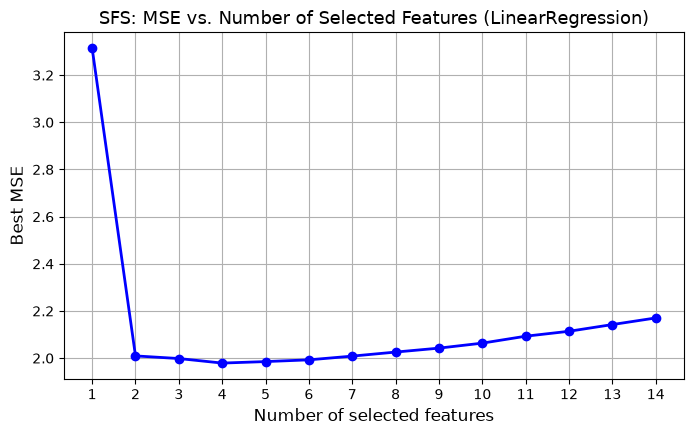

Linear Regression with SBS (Plotting Enabled):

Iteration 1: MSE = 2.1704843537187894
11111111111111: id	cylinders	displacement	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 2: MSE = 2.1376427808690637
11011111111111: id	cylinders	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 3: MSE = 2.1080443914583924
11011111011111: id	cylinders	horsepower	weight_lbs	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 4: MSE = 2.0788819758312003
11010111011111: id	cylinders	horsepower	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 5: MSE = 2.0535888046726547
01010111011111: cylinders	horsepower	weight_kg	acceleration	model_year	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 6: MSE = 2.03219246598

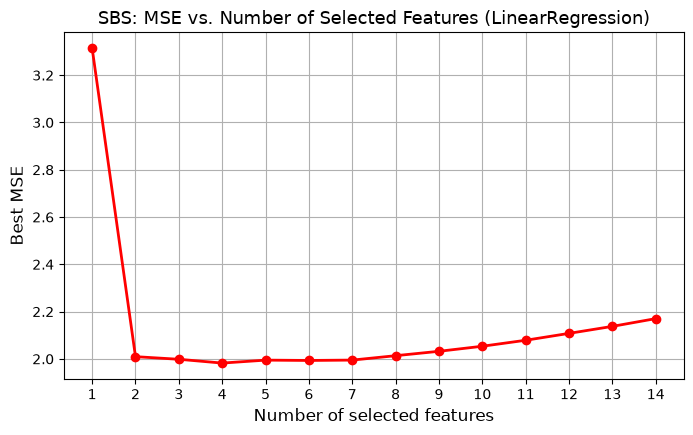

In [54]:
print("Linear Regression with SFS (Plotting Enabled):\n")
SFS(X, y, LinearRegression(), feature_names, plot=True)

print("Linear Regression with SBS (Plotting Enabled):\n")
SBS(X, y, LinearRegression(), feature_names, plot=True)

## 2. KNN (Best $k=2$) with SFS and SBS (Plotting Enabled)

KNN (k = 2) with SFS (Plotting Enabled):

Iteration 1: MSE = 5.174025000000001
01000000000000: cylinders

Iteration 2: MSE = 3.6490250000000004
01000001000000: cylinders	model_year

Iteration 3: MSE = 3.2698875000000003
01000011000000: cylinders	acceleration	model_year

Iteration 4: MSE = 2.4417750000000007
01100011000000: cylinders	displacement	acceleration	model_year

Iteration 5: MSE = 2.529312500000001
01100011100000: cylinders	displacement	acceleration	model_year	color

Iteration 6: MSE = 3.2081750000000007
01110011100000: cylinders	displacement	horsepower	acceleration	model_year	color

Iteration 7: MSE = 3.365825000000001
01110011100010: cylinders	displacement	horsepower	acceleration	model_year	color	more_info_4

Iteration 8: MSE = 3.8326000000000002
01110011110010: cylinders	displacement	horsepower	acceleration	model_year	color	more_info_1	more_info_4

Iteration 9: MSE = 4.121425
01110111110010: cylinders	displacement	horsepower	weight_kg	acceleration	model_year	color	more_info_

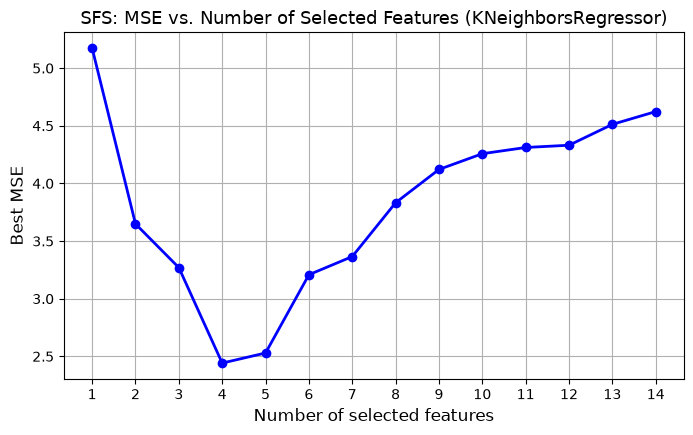

KNN (k = 2) with SBS (Plotting Enabled):

Iteration 1: MSE = 4.62325
11111111111111: id	cylinders	displacement	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_4	more_info_5

Iteration 2: MSE = 4.3935375
11111111111101: id	cylinders	displacement	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3	more_info_5

Iteration 3: MSE = 4.2975875
11111111111100: id	cylinders	displacement	horsepower	weight_lbs	weight_kg	acceleration	model_year	color	more_info_1	more_info_2	more_info_3

Iteration 4: MSE = 4.126949999999999
11111011111100: id	cylinders	displacement	horsepower	weight_lbs	acceleration	model_year	color	more_info_1	more_info_2	more_info_3

Iteration 5: MSE = 4.126949999999999
10111011111100: id	displacement	horsepower	weight_lbs	acceleration	model_year	color	more_info_1	more_info_2	more_info_3

Iteration 6: MSE = 4.126949999999999
10111001111100: id	displacement	horsepower	weight_l

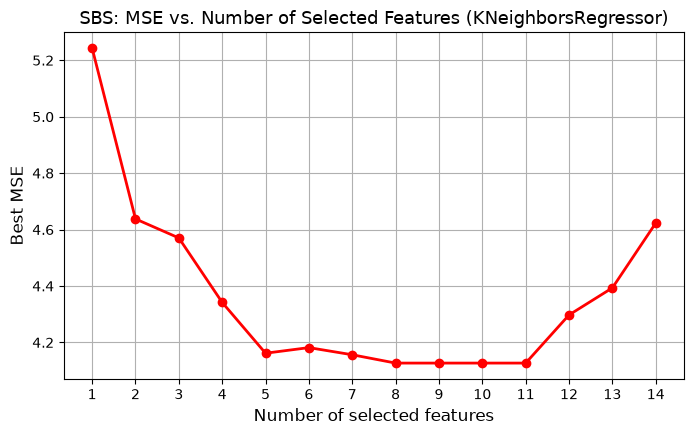

In [55]:
best_knn = KNeighborsRegressor(n_neighbors=2)

print(f"KNN (k = {best_k}) with SFS (Plotting Enabled):\n")
SFS(X, y, best_knn, feature_names, plot=True)

print(f"KNN (k = {best_k}) with SBS (Plotting Enabled):\n")
SBS(X, y, best_knn, feature_names, plot=True)

## Analysis of Results and Plots
### Task 1: Comparison between SFS and SBS for Linear Regression
SFS:
- Achieved lowest MSE of 1.9791 (R2 = 0.8574) at 4 features: displacement, weight_kg, model_year, and more_info_4.
- The most informative single feature in iteration 1 was weight_kg.
SBS:
- Achieved lowest MSE of 1.9824 (R2 = 0.8565) at 4 features: cylinders, weight_kg, model_year, and more_info_4.
Feature Consistency:
- Both methods selected almost identical core feature subsets (weight_kg, model_year, more_info_4). SFS included displacement whereas SBS included cylinders. Because engine displacement and cylinder count are probably strongly correlated, either feature captures the engine size, leading to almost identical overall performance.
- Both forward and backward feature selection drastically reduced dimensionality while improving model scores and generalizability

### Task 2: Unweighted KNN Performance with k = 1-9
- With SFS and k=2 the best overall performance was achieved with MSE of 2.4418 and R2 Score of 0.8254 using the four features cylinders, displacement, acceleration and model_year.
- Small to moderate k values (2<=k<=7) consistently outperformed k=1 and k=9 due to high variance and sensitivity to sample nose (k=1) and over-smoothing (k=9)

### Task 3: Analysis of MSE vs. Number of selected features (Plots)
Linear Regression:
- SFS shows a sharp drop in MSE from 1 to 2 features and improves slighlty as the number of features increases, reaching a minimum at 4 features, then steadily increasing as more features are added, indicating the detrimental effect of redundant/noisy features and multicollinearity.
- SBS starts with 14 features and steadily reduces MSE until reaching the optimum at 4 features, then sharply increases as essential features are removed, indicating the importance of retaining key physical predictors. Same as in SFS, the MSE spikes sharply at 1 feature remaining.

KNN:
- SFS drops from 1 to 4 features to MSE 2.4418 and then degrades significantly to 4.4172 when all 14 features are included.
- In SBS the MSE drops low for 5 to 11 features, degrading for fewer or more features. But all models have a high prediction error (MSE = 4.1269 at lowest)

Comparison:
- Linear Regression outperforms unweighted KNN on this dataset with MSE = 1.9791 and R2 = 0.8574 vs. MSE = 2.4418 and R2 = 0.8254.
- For both model types, feature selection is crucial for preventing overfitting and improving prediction precision. But for KNN SFS achieves strongly better results.

---
Assignee: Jakob Benedikt Wilmesmeier